# 00. Import Library

In [1]:
import os
import pickle
import tarfile
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

# 01. Data preparation

In [2]:
BASE = 'cifar-10-batches-py'

if not os.path.isdir(BASE):
    tarfile.open('cifar-10-python.tar.gz').extractall()


def unpickle(file):   # loader given on the CIFAR-10 website
    with open(file, 'rb') as f:
        return pickle.load(f, encoding='bytes')


# train : data_batch_1 ~ 5 (50,000 images), test : test_batch (10,000 images)
train_batches = [unpickle(f'{BASE}/data_batch_{i}') for i in range(1, 6)]
X_train = np.concatenate([b[b'data'] for b in train_batches]).astype(np.float32)
y_train = np.concatenate([b[b'labels'] for b in train_batches])

test_batch = unpickle(f'{BASE}/test_batch')
X_test = np.array(test_batch[b'data']).astype(np.float32)
y_test = np.array(test_batch[b'labels'])

CLASSES = [c.decode() for c in unpickle(f'{BASE}/batches.meta')[b'label_names']]

print('train :', X_train.shape, y_train.shape)
print('test  :', X_test.shape, y_test.shape)
print('classes :', CLASSES)
print('images per class (train) :', np.bincount(y_train))
print('images per class (test)  :', np.bincount(y_test))

train : (50000, 3072) (50000,)
test  : (10000, 3072) (10000,)
classes : ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
images per class (train) : [5000 5000 5000 5000 5000 5000 5000 5000 5000 5000]
images per class (test)  : [1000 1000 1000 1000 1000 1000 1000 1000 1000 1000]


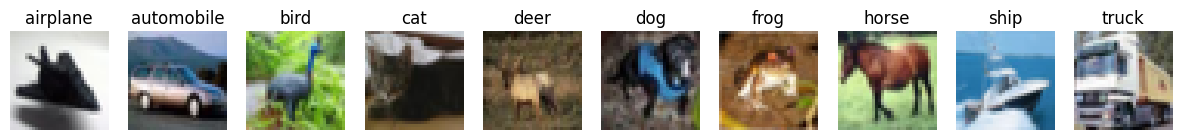

In [3]:
# one train image per class (3072 vector -> 32x32x3)
plt.figure(figsize=(15, 2))
for c in range(10):
    i = np.where(y_train == c)[0][0]
    plt.subplot(1, 10, c + 1)
    plt.imshow(X_train[i].reshape(3, 32, 32).transpose(1, 2, 0).astype(np.uint8))
    plt.title(CLASSES[c])
    plt.axis('off')
plt.show()

# 02. Distance metrics & KNN

KNN with L1 (`manhattan`) and L2 (`euclidean`) distance on raw pixels (3072-dim) : find the $k$ nearest train images and take a majority vote of their labels.

# 03. 5-fold split & evaluation metrics

The 50,000 train images are split into 5 folds with `StratifiedKFold`, so every fold keeps the same class ratio.
The test set is not used until the final evaluation.

| Score | Formula | Meaning |
|---|---|---|
| Accuracy | $\frac{\text{correct}}{\text{total}}$ | How many images are classified correctly |
| Precision | $\frac{TP}{TP + FP}$ | Of the images predicted as a class, how many really are |
| Recall | $\frac{TP}{TP + FN}$ | Of the images of a class, how many are found |
| F1-score | $\frac{2 \cdot Precision \cdot Recall}{Precision + Recall}$ | Harmonic mean of precision and recall |

Precision, Recall and F1 are computed per class and then averaged (`average='macro'`).
Every class has the same number of images here, so **macro Recall is always equal to Accuracy**.

In [4]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
folds = list(skf.split(X_train, y_train))

for fold, (tr, val) in enumerate(folds, 1):
    print(f'fold {fold} : train {len(tr)}, validation {len(val)}, validation images per class {np.bincount(y_train[val])}')

fold 1 : train 40000, validation 10000, validation images per class [1000 1000 1000 1000 1000 1000 1000 1000 1000 1000]
fold 2 : train 40000, validation 10000, validation images per class [1000 1000 1000 1000 1000 1000 1000 1000 1000 1000]
fold 3 : train 40000, validation 10000, validation images per class [1000 1000 1000 1000 1000 1000 1000 1000 1000 1000]
fold 4 : train 40000, validation 10000, validation images per class [1000 1000 1000 1000 1000 1000 1000 1000 1000 1000]
fold 5 : train 40000, validation 10000, validation images per class [1000 1000 1000 1000 1000 1000 1000 1000 1000 1000]


# 04_1. 5-fold cross-validation

L1 and L2 with $k$ = 1, 3, 5, 7, 15 on the same 5 folds (train 40,000 / validation 10,000).
Computing the distances is the slow part, so the 15 nearest neighbors are found once per fold and every $k$ uses the first $k$ of them.

With 10 classes, ties in the vote are common (e.g. 3 neighbors with 3 different labels), so `vote()` breaks a tie with the nearest neighbor.
The default of sklearn / scipy (smaller class index wins) is not used, because it favors classes like airplane and automobile only because of their index.

In [5]:
METRICS = {'L1': 'manhattan', 'L2': 'euclidean'}
K_LIST = [1, 3, 5, 7, 15]
SCORES = ['Accuracy', 'Precision', 'Recall', 'F1']


def get_scores(y_true, y_pred):
    return {'Accuracy': accuracy_score(y_true, y_pred),
            'Precision': precision_score(y_true, y_pred, average='macro', zero_division=0),
            'Recall': recall_score(y_true, y_pred, average='macro'),
            'F1': f1_score(y_true, y_pred, average='macro')}


def vote(labels):   # labels of the k nearest neighbors, nearest first
    counts = np.bincount(labels, minlength=10)
    winners = np.where(counts == counts.max())[0]
    for label in labels:   # tie -> the class of the nearest neighbor
        if label in winners:
            return label


results = []
for name, metric in METRICS.items():
    for fold, (tr, val) in enumerate(folds, 1):
        start = time.time()
        nn = NearestNeighbors(n_neighbors=max(K_LIST), metric=metric).fit(X_train[tr])
        idx = nn.kneighbors(X_train[val], return_distance=False)   # (10000, 15), nearest first
        neighbor_labels = y_train[tr][idx]

        for k in K_LIST:
            pred = np.array([vote(row[:k]) for row in neighbor_labels])   # majority vote of the k nearest
            results.append({'metric': name, 'fold': fold, 'k': k, **get_scores(y_train[val], pred)})
        print(f'{name} fold {fold} done ({time.time() - start:.0f} s)')

cv = pd.DataFrame(results)

L1 fold 1 done (255 s)


L1 fold 2 done (245 s)


L1 fold 3 done (1724 s)


L1 fold 4 done (241 s)


L1 fold 5 done (241 s)


L2 fold 1 done (36 s)


L2 fold 2 done (36 s)


L2 fold 3 done (36 s)


L2 fold 4 done (36 s)


L2 fold 5 done (36 s)


# 04_2. Effect of k

Mean and standard deviation over the 5 folds.

In [6]:
summary = cv.groupby(['metric', 'k'])[SCORES].agg(['mean', 'std']).round(4)
summary

Accuracy         Precision          Recall              F1        
              mean     std      mean     std    mean     std    mean     std
metric k                                                                    
L1     1    0.3713  0.0017    0.4156  0.0045  0.3713  0.0017  0.3694  0.0025
       3    0.3755  0.0024    0.4268  0.0048  0.3755  0.0024  0.3722  0.0025
       5    0.3791  0.0030    0.4429  0.0042  0.3791  0.0030  0.3742  0.0026
       7    0.3782  0.0019    0.4476  0.0045  0.3782  0.0019  0.3719  0.0011
       15   0.3702  0.0034    0.4547  0.0058  0.3702  0.0034  0.3618  0.0030
L2     1    0.3411  0.0015    0.3976  0.0044  0.3411  0.0015  0.3348  0.0025
       3    0.3435  0.0033    0.4080  0.0043  0.3435  0.0033  0.3351  0.0031
       5    0.3486  0.0029    0.4324  0.0035  0.3486  0.0029  0.3380  0.0029
       7    0.3465  0.0042    0.4390  0.0066  0.3465  0.0042  0.3339  0.0042
       15   0.3356  0.0032    0.4464  0.0068  0.3356  0.0032  0.3189  0.0034

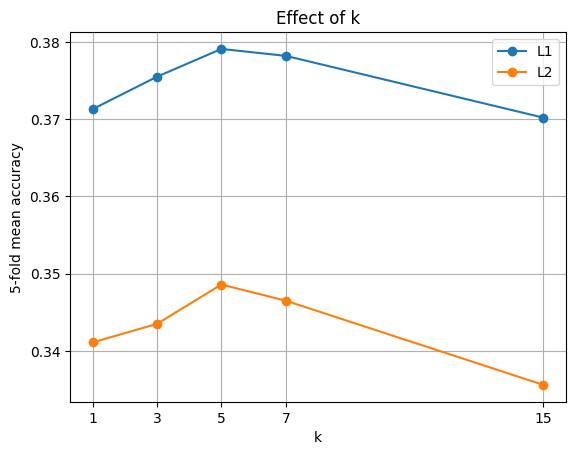

In [7]:
for name in METRICS:
    plt.plot(K_LIST, summary.loc[name][('Accuracy', 'mean')], marker='o', label=name)
plt.xlabel('k')
plt.ylabel('5-fold mean accuracy')
plt.title('Effect of k')
plt.xticks(K_LIST)
plt.grid(True)
plt.legend()
plt.show()

# 04_3. Effect of distance metric

The best $k$ of each metric is the one with the highest 5-fold mean accuracy (the test set is not used).

In [8]:
best_k = {}
for name in METRICS:
    acc = summary.loc[name][('Accuracy', 'mean')]
    best_k[name] = acc.idxmax()
    print(f'{name} : best k = {best_k[name]}, 5-fold accuracy = {acc.max():.4f}')

best_metric = 'L1' if summary.loc[('L1', best_k['L1']), ('Accuracy', 'mean')] > summary.loc[('L2', best_k['L2']), ('Accuracy', 'mean')] else 'L2'
print('\nBest model (5-fold) :', best_metric, ', k =', best_k[best_metric])

L1 : best k = 5, 5-fold accuracy = 0.3791
L2 : best k = 5, 5-fold accuracy = 0.3486

Best model (5-fold) : L1 , k = 5


In [9]:
# accuracy of each fold at the best k : is L1 vs L2 the same in every fold?
per_fold = pd.DataFrame({name: cv[(cv['metric'] == name) & (cv['k'] == best_k[name])]['Accuracy'].values for name in METRICS},
                        index=[1, 2, 3, 4, 5])
per_fold['L1 - L2'] = per_fold['L1'] - per_fold['L2']
per_fold.index.name = 'fold'
per_fold.round(4)

,L1,L2,L1 - L2
fold,,,
1,0.3819,0.3519,0.0300
2,0.3764,0.3472,0.0292
3,0.3777,0.3444,0.0333
4,0.3767,0.3499,0.0268
5,0.3826,0.3495,0.0331


# 05_1. Final evaluation on the test set

Each metric with its best $k$ from 04_3 : train on all 50,000 images, test on the 10,000 images of `test_batch`.

In [10]:
test_results, test_pred = [], {}
for name, metric in METRICS.items():
    start = time.time()
    nn = NearestNeighbors(n_neighbors=best_k[name], metric=metric).fit(X_train)
    idx = nn.kneighbors(X_test, return_distance=False)
    test_pred[name] = np.array([vote(row) for row in y_train[idx]])
    test_results.append({'metric': name, 'k': best_k[name], **get_scores(y_test, test_pred[name])})
    print(f'{name} done ({time.time() - start:.0f} s)')

pd.DataFrame(test_results).round(4)

L1 done (302 s)


L2 done (44 s)


,metric,k,Accuracy,Precision,Recall,F1
0,L1,5,0.3921,0.4560,0.3921,0.3890
1,L2,5,0.3556,0.4367,0.3556,0.3452


# 05_2. Per-class results

In [11]:
pred = test_pred[best_metric]
print(f'[{best_metric}, k={best_k[best_metric]}] test set\n')
print(classification_report(y_test, pred, target_names=CLASSES, digits=4))

[L1, k=5] test set

              precision    recall  f1-score   support

    airplane     0.4500    0.5440    0.4925      1000
  automobile     0.6839    0.2640    0.3810      1000
        bird     0.2644    0.4170    0.3236      1000
         cat     0.3130    0.2160    0.2556      1000
        deer     0.2633    0.5160    0.3486      1000
         dog     0.4286    0.3120    0.3611      1000
        frog     0.3763    0.3500    0.3627      1000
       horse     0.6455    0.3150    0.4234      1000
        ship     0.4307    0.6990    0.5330      1000
       truck     0.7042    0.2880    0.4088      1000

    accuracy                         0.3921     10000
   macro avg     0.4560    0.3921    0.3890     10000
weighted avg     0.4560    0.3921    0.3890     10000



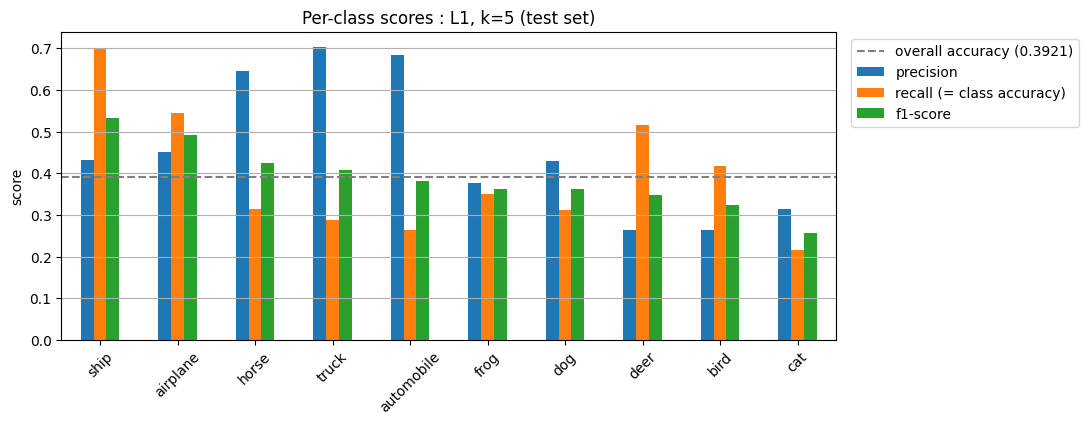

In [12]:
report = classification_report(y_test, pred, target_names=CLASSES, output_dict=True)
per_class = pd.DataFrame(report).T.loc[CLASSES, ['precision', 'recall', 'f1-score']]
per_class = per_class.rename(columns={'recall': 'recall (= class accuracy)'})
per_class.sort_values('f1-score', ascending=False).plot.bar(figsize=(10, 4))
plt.axhline(report['accuracy'], color='gray', linestyle='--', label=f"overall accuracy ({report['accuracy']:.4f})")
plt.title(f'Per-class scores : {best_metric}, k={best_k[best_metric]} (test set)')
plt.ylabel('score')
plt.xticks(rotation=45)
plt.grid(axis='y')
plt.legend(bbox_to_anchor=(1.01, 1), loc='upper left')
plt.show()

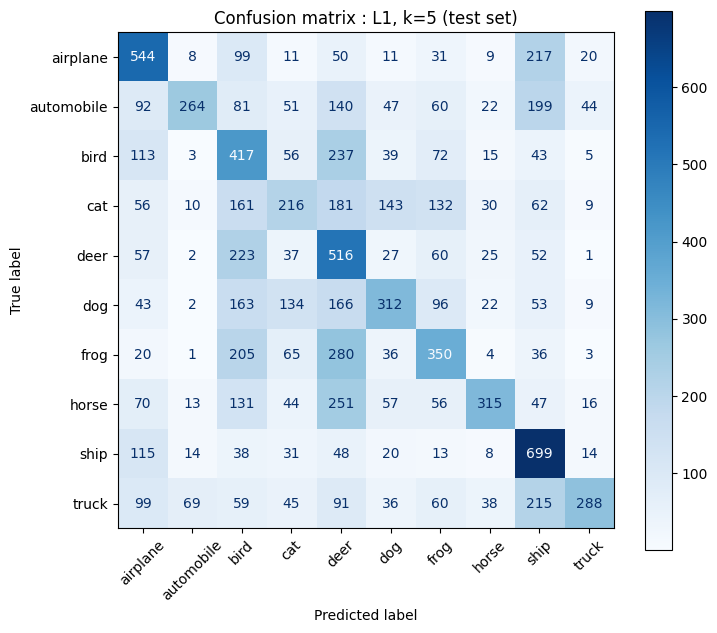

In [13]:
fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=CLASSES, xticks_rotation=45, cmap='Blues', ax=ax)
plt.title(f'Confusion matrix : {best_metric}, k={best_k[best_metric]} (test set)')
plt.show()

# 06. Comparison & explanation

| Metric | Best k (5-fold) | 5-fold Accuracy | Test Accuracy | Test Precision | Test Recall | Test F1 |
|---|---|---|---|---|---|---|
| **L1** | **5** | **0.3791 ± 0.0030** | **0.3921** | **0.4560** | **0.3921** | **0.3890** |
| L2 | 5 | 0.3486 ± 0.0029 | 0.3556 | 0.4367 | 0.3556 | 0.3452 |

- **Best model : L1, k=5**, selected by 5-fold CV only. Test accuracy is 39.2% (chance level 10%), a bit higher than the 5-fold 37.9%, likely because the final model uses 50,000 instead of 40,000 train images.
- **Effect of k** : k=5 is the best for both metrics. k=1 is noisy because a single neighbor decides, and k=15 is worse because farther, less similar images join the vote.
- **Effect of metric** : L1 > L2 in all 5 folds, by 2.7 ~ 3.3 points. L2 squares the pixel differences, so a few very different pixels dominate the distance.
- **Scores** : Recall equals Accuracy because every class has the same number of images. Precision is higher than Accuracy because rarely predicted classes (truck, automobile, horse) have high precision (0.65 ~ 0.70) but low recall (0.26 ~ 0.32).
- **Limit** : raw-pixel distance compares color and background, not objects (truck / automobile -> ship : 215 / 199, frog / horse -> deer : 280 / 251). Prediction is also slow, since every query is compared with every train image : 241 ~ 255 s per fold for L1 and 36 s per fold for L2 (04_1), 302 s and 44 s on the test set (05_1). L1 fold 3 took 1724 s, an outlier : every fold has the same size (40,000 / 10,000), so the extra time comes from the run environment (wall-clock time), not from the method.